# 04 · Forecasting weekly PM2.5: rolling-origin backtest, calibration, 1-week test, 2020 outlook
**What this notebook answers**
1. Which 52-week-ahead model is best, judged on three expanding-window origins (end of 2016, 2017, 2018 → forecasts for 2017, 2018, 2019)?
   Everything (Fourier order, ARMA order, level/trend treatment) is re-selected at each origin using only data before it.
2. Are the residuals clean (with the diffuse-initialisation residuals removed) and are the intervals calibrated?
3. Does weather help one week ahead, when tested fairly (lagged weather) versus with hindsight (same-week weather = oracle)?
4. What does a model fitted on 2015-2019 say about each month of 2020, and what does the gap to the lockdown months look like?

**Design rules.** Target: weekly mean PM2.5, modelled as log (so the point forecast `exp(mu)` is a *median*; mean forecasts use
`exp(mu + sd²/2)` with the horizon-specific sd). Season length 365.25/7 weeks. No weather in the 52-week models (notebook 03:
last week's weather adds nothing at the weekly scale and future weather is unknown). The 2020 lockdown never enters model selection.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v] = "1"
import sys
sys.path.append("..")

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from src import forecast as F
from src.aqi import CATEGORIES, pm25_category
from src.data import PROCESSED, RESULTS
from src.plots import use_style, savefig, BLUE, ORANGE, AQUA, NEUTRAL, INK, INK_2, MUTED, SURFACE
from src.tsa import week_index, doy_anomaly

warnings.filterwarnings("ignore")
use_style()
weekly = pd.read_csv(PROCESSED / "delhi_weekly.csv", index_col="Date", parse_dates=True).asfreq("W-SUN")
daily = pd.read_csv(PROCESSED / "delhi_daily.csv", index_col="Date", parse_dates=True).asfreq("D")
y, raw = weekly["log_pm25"], weekly["pm25"]
assert y.notna().all() and len(y) == 287
key = {}
SEL = "Fourier+ARMA (selected)"
print(F.ORIGINS)

{2017: '2016-12-25', 2018: '2017-12-31', 2019: '2018-12-30'}


## 1. Models
| Model | What it is |
|---|---|
| Seasonal naive | the value 52 weeks earlier (52 weeks, not the same calendar week in 53-week years) |
| Climatology | mean log PM2.5 of the same calendar week over the training years |
| Climatology + AR(1) | climatology plus an AR(1) on the weekly anomalies |
| Linear regression | OLS on 3 Fourier harmonics + a linear time trend (prediction interval includes parameter uncertainty, so it widens with the horizon) |
| LSTM (small) | 1 layer, 16 units, seeded and deterministic, recursive one-step on anomalies; each input row pairs the anomaly with the calendar features of **its own week** (an alignment bug in the first version was fixed); interval sd from in-sample recursive h-step errors. Small-data baseline only. **Its interval is a heuristic** (the h-step error spread is estimated in-sample, so it is optimistic) |
| Fourier+ARMA const / linear | dynamic harmonic regression (DHR): K=3 harmonics, AR(1) errors, constant or linear-trend level |
| **Fourier+ARMA (selected)** | K ∈ 1..5 and (p,q) by AICc inside each trend type (constant / linear / random-walk errors); the trend type chosen by validation on the *last training year*. The random-walk option makes the errors **ARIMA(p,1,q)**, so "ARMA" in the label covers both. Non-converged fits are rejected and counted. The procedure was fixed in the code before the final runs, but 2019 had been looked at in earlier iterations of the project, so it is not a pristine hold-out. |
| SARIMA D=1 / D=0 | the benchmark from the draft: (1,0,1)(0,1,1)₅₂, and (1,0,1)(1,0,0)₅₂ **with a constant** (the draft omitted it) |

In [2]:
models = {
    "Seasonal naive": F.seasonal_naive, "Climatology": F.climatology, "Climatology + AR(1)": F.clim_ar1,
    "Linear regression": F.linreg, "LSTM (small)": F.lstm,
    "Fourier+ARMA const": F.dhr_fixed("const"), "Fourier+ARMA linear": F.dhr_fixed("linear"),
    SEL: F.dhr, "SARIMA D=1": F.sarima_D1, "SARIMA D=0": F.sarima_D0,
}
bt, fcs = F.backtest(y, raw, models, n_jobs=10, verbose=False)
bt.to_csv(RESULTS / "fc_backtest_metrics.csv", index=False)
long = pd.concat([pd.DataFrame({"fold": f, "model": m, "date": o["idx"], "actual": o["actual"], "mu": o["mu"],
                                "sd": o["sd"] if o["sd"] is not None else np.nan})
                  for f, d_ in fcs.items() for m, o in d_.items()])
long.to_csv(RESULTS / "fc_backtest_forecasts.csv", index=False)
specs = {f: fcs[f][SEL]["spec"] for f in fcs}
print("Selected specification per origin:"); display(pd.DataFrame(specs).T[["trend", "K", "p", "q", "inner_mae"]])

Selected specification per origin:


,trend,K,p,q,inner_mae
2017,rw,5,1,1,"{'const': 29.500542621119926, 'linear': 47.599..."
2018,const,5,1,1,"{'const': 30.66527919983907, 'linear': 37.6800..."
2019,rw,5,1,1,"{'const': 23.425849242714854, 'linear': 21.234..."


## 2. Backtest results (52 weeks ahead, MAE in µg/m³ on the original scale)
Folds 2018 and 2019 are the main evidence (3 and 4 training seasons); 2017 (only 2 training years) is a stress test. Climatology is the model to beat. Each fold is 52 weeks starting the week after the origin (the 2017 fold ends 24 Dec 2017, not 31 Dec).

In [3]:
tab = bt.pivot(index="model", columns="fold", values="MAE")
tab["mean 2018-19"] = tab[[2018, 2019]].mean(axis=1)
tab["mean all 3"] = tab[[2017, 2018, 2019]].mean(axis=1)
tab = tab.sort_values("mean 2018-19")
tab.round(1).to_csv(RESULTS / "fc_backtest_mae.csv")
display(tab.round(1))
extra = bt.groupby("model")[["RMSE", "logMAE", "MAE_winter", "MAE_other", "bias"]].mean().loc[tab.index]
extra["coverage95"] = bt.groupby("model")["coverage"].mean()
extra["winkler"] = bt.groupby("model")["winkler"].mean()
display(extra.round(2))

fold,2017,2018,2019,mean 2018-19,mean all 3
model,,,,,
Fourier+ARMA linear,35.9,19.7,24.0,21.9,26.5
Linear regression,35.9,20.0,24.9,22.5,26.9
SARIMA D=1,53.8,21.1,27.5,24.3,34.1
Climatology + AR(1),30.7,21.7,27.3,24.5,26.6
Fourier+ARMA (selected),31.5,23.4,25.7,24.6,26.9
Climatology,31.0,21.8,27.8,24.8,26.9
Fourier+ARMA const,30.6,22.0,29.3,25.7,27.3
Seasonal naive,38.4,29.0,30.3,29.6,32.6
LSTM (small),36.3,28.3,54.3,41.3,39.7


,RMSE,logMAE,MAE_winter,MAE_other,bias,coverage95,winkler
model,,,,,,,
Fourier+ARMA linear,40.28,0.23,46.53,16.80,-4.43,0.86,237.50
Linear regression,40.83,0.24,47.40,17.01,-3.60,0.88,220.47
SARIMA D=1,58.73,0.26,59.47,21.81,-18.24,0.85,304.16
Climatology + AR(1),38.26,0.25,40.05,20.01,-8.13,0.78,256.63
Fourier+ARMA (selected),39.45,0.24,45.80,17.67,-7.54,0.85,194.50
Climatology,38.39,0.25,40.96,20.01,-7.62,0.78,255.77
Fourier+ARMA const,40.91,0.25,44.40,18.99,-6.49,0.87,238.73
Seasonal naive,52.78,0.28,54.45,21.94,-9.94,0.92,221.65
LSTM (small),57.79,0.34,64.83,27.45,-14.82,0.52,611.08


In [4]:
# Paired loss differences against climatology: moving-block bootstrap (8-week blocks) of the weekly absolute-error differences.
def abs_err(model, folds):
    return [np.abs(fcs[f][model]["actual"] - np.exp(fcs[f][model]["mu"])) for f in folds]   # one array per fold: blocks never cross folds

ld = []
for label, folds in [("folds 2018+2019", [2018, 2019]), ("all three folds", [2017, 2018, 2019])]:
    for m in models:
        if m == "Climatology":
            continue
        dm_, lo, hi = F.block_bootstrap_diff(abs_err(m, folds), abs_err("Climatology", folds))
        ld.append({"folds": label, "model": m, "mean_MAE_diff_vs_climatology": dm_, "ci_lo": lo, "ci_hi": hi,
                   "verdict": "better" if hi < 0 else ("worse" if lo > 0 else "indistinguishable")})
ld = pd.DataFrame(ld).round(2); ld.to_csv(RESULTS / "fc_loss_diff.csv", index=False)
display(ld[ld.folds == "folds 2018+2019"])

,folds,model,mean_MAE_diff_vs_climatology,ci_lo,ci_hi,verdict
0,folds 2018+2019,Seasonal naive,4.84,0.94,8.96,worse
1,folds 2018+2019,Climatology + AR(1),-0.30,-0.80,0.02,indistinguishable
2,folds 2018+2019,Linear regression,-2.33,-5.83,1.91,indistinguishable
3,folds 2018+2019,LSTM (small),16.54,6.62,27.75,worse
4,folds 2018+2019,Fourier+ARMA const,0.86,-2.09,4.32,indistinguishable
5,folds 2018+2019,Fourier+ARMA linear,-2.94,-6.12,0.68,indistinguishable
6,folds 2018+2019,Fourier+ARMA (selected),-0.23,-2.91,2.77,indistinguishable
7,folds 2018+2019,SARIMA D=1,-0.53,-1.91,0.98,indistinguishable
8,folds 2018+2019,SARIMA D=0,18.67,13.13,23.88,worse


**Reading it.** A negative difference means lower error than climatology. The interval is wide because 52 consecutive weekly errors
within one forecast path are strongly dependent: three origins are far too few for a sharp significance claim, and
we say "indistinguishable" whenever the interval contains 0. The earlier draft's 2019 comparison (SARIMA 27.5 vs climatology 27.8)
is such a case.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


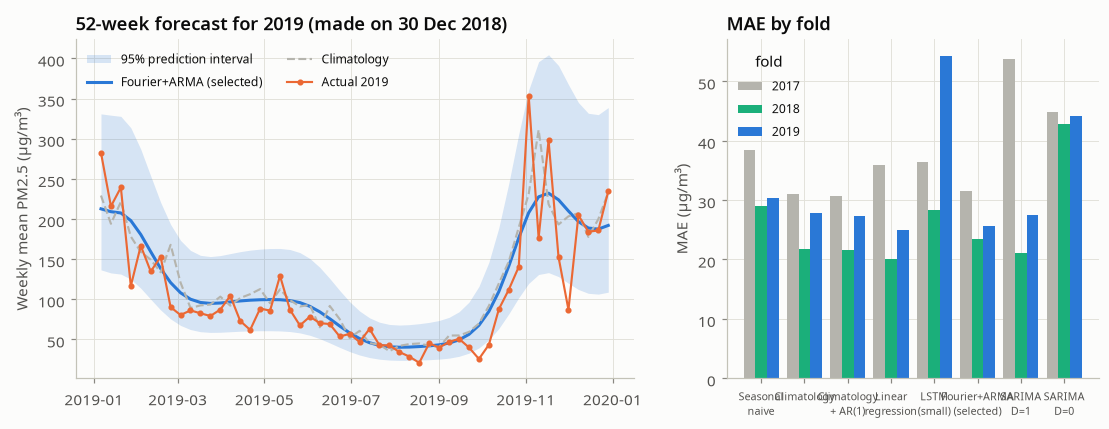

In [5]:
sel_name = SEL
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.5, 1]})
f19 = fcs[2019]; idx19 = f19[sel_name]["idx"]
mu, sd = f19[sel_name]["mu"], f19[sel_name]["sd"]
ax = axes[0]
ax.fill_between(idx19, np.exp(mu - 1.96 * sd), np.exp(mu + 1.96 * sd), color=BLUE, alpha=0.18, lw=0, label="95% prediction interval")
ax.plot(idx19, np.exp(mu), color=BLUE, lw=2, label=f"{sel_name}")
ax.plot(idx19, np.exp(f19["Climatology"]["mu"]), color=NEUTRAL, lw=1.4, ls="--", label="Climatology")
ax.plot(idx19, f19[sel_name]["actual"], color=ORANGE, lw=1.4, marker="o", ms=3, label="Actual 2019")
ax.set_ylabel("Weekly mean PM2.5 (µg/m³)"); ax.legend(ncols=2, fontsize=8)
ax.set_title("52-week forecast for 2019 (made on 30 Dec 2018)")
ax = axes[1]
show = ["Seasonal naive", "Climatology", "Climatology + AR(1)", "Linear regression", "LSTM (small)", SEL, "SARIMA D=1", "SARIMA D=0"]
x = np.arange(len(show)); wdt = 0.27
for k, (f, c) in enumerate([(2017, NEUTRAL), (2018, AQUA), (2019, BLUE)]):
    ax.bar(x + (k - 1) * wdt, [tab.loc[m, f] for m in show], wdt, color=c, label=str(f))
ax.set_xticks(x, [s.replace("Fourier+ARMA (selected)", "Fourier+ARMA\n(selected)").replace(" ", "\n", 1) for s in show], fontsize=7)
ax.set_ylabel("MAE (µg/m³)"); ax.legend(title="fold", fontsize=8); ax.set_title("MAE by fold")
savefig(fig, "13_backtest"); plt.show()

In [6]:
# SARIMA D=0 with vs without a constant, same orders, same three folds (replaces the unsupported "39.7 -> 30.6" remark of the first write-up)
d0 = {"no constant": F.sarima((1, 0, 1), (1, 0, 0, 52), trend="n"), "with constant": F.sarima((1, 0, 1), (1, 0, 0, 52), trend="c")}
bt0, _ = F.backtest(y, raw, d0, n_jobs=6, verbose=False)
d0tab = bt0.pivot(index="model", columns="fold", values="MAE")
for f in (2017, 2018, 2019):
    d0tab.loc["Climatology (reference)", f] = bt[(bt.model == "Climatology") & (bt.fold == f)]["MAE"].iloc[0]
d0tab.round(1).to_csv(RESULTS / "fc_sarima_d0_constant.csv"); display(d0tab.round(1))
key["sarima_d0_const"] = d0tab.round(2).to_dict()

fold,2017,2018,2019
model,,,
no constant,76.9,61.0,92.1
with constant,44.9,42.8,44.1
Climatology (reference),31.0,21.8,27.8


In [7]:
# Fit details of the D=0 candidates (the no-constant fit is numerically fragile: AR root near 1), so that the comparison can be audited
import statsmodels, scipy, sys
det = []
for fold, origin in F.ORIGINS.items():
    tr_ = y.loc[:origin]
    for nm, tr_arg in (("no constant", "n"), ("with constant", "c")):
        r_ = F._fit(SARIMAX(tr_, order=(1, 0, 1), seasonal_order=(1, 0, 0, 52), trend=tr_arg))
        det.append({"fold": fold, "variant": nm, "converged": F.converged(r_), "loglik": float(r_.llf), "ar1": float(r_.params["ar.L1"]),
                    "seasonal_ar52": float(r_.params["ar.S.L52"]), "n_params": len(r_.params)})
det = pd.DataFrame(det); det["statsmodels"] = statsmodels.__version__; det["scipy"] = scipy.__version__; det["python"] = sys.version.split()[0]
det.round(4).to_csv(RESULTS / "fc_sarima_d0_fit_details.csv", index=False); display(det.round(4))

,fold,variant,converged,loglik,ar1,seasonal_ar52,n_params,statsmodels,scipy,python
0,2017,no constant,True,-7.0451,0.9989,0.2636,4,0.15.0,1.18.1,3.12.16
1,2017,with constant,True,-2.5802,0.9156,0.2921,5,0.15.0,1.18.1,3.12.16
2,2018,no constant,True,-28.6176,0.9988,0.2732,4,0.15.0,1.18.1,3.12.16
3,2018,with constant,True,-23.3013,0.9217,0.3025,5,0.15.0,1.18.1,3.12.16
4,2019,no constant,True,-33.2941,0.9995,0.3406,4,0.15.0,1.18.1,3.12.16
5,2019,with constant,True,-26.9299,0.9216,0.3660,5,0.15.0,1.18.1,3.12.16


**Reading it.** Without a constant the AR coefficient sits at about 1 and the fit is fragile: an outside audit refitting with another statsmodels version and a log column computed in a slightly different way (differences below 1e-15) obtained 64.8 (2018) and 81.5-92.1 (2019) instead of 61.0 and 92.1. With a constant the three folds reproduce (44.9 / 42.8 / 44.1). The exact no-constant MAEs should therefore be read as "much worse than climatology, 60-90", not as precise values; the fitted parameters and software versions are saved above.

**Reading it.** Adding the constant changes the SARIMA D=0 error by the amounts above (same orders, same folds); D=0 stays clearly worse than climatology either way.

## 3. Residual diagnostics (the draft's Ljung–Box result was an artifact)
`SARIMAX` with `D=1` initialises the first 52 seasonal states diffusely, so the first 52 in-sample residuals are as large as the series level
(about 5 on the log scale) and must be excluded (`res.loglikelihood_burn`). The draft ran Ljung–Box on all residuals and got p ≈ 0 at every lag.
Below: the same model with and without the exclusion, next to the selected Fourier+ARMA model, all fitted on 2015–2018.

In [8]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
tr19 = y.loc[:F.ORIGINS[2019]]
sp = specs[2019]
res_dhr = F._fit_dhr(tr19, sp["K"], sp["p"], sp["q"], sp["trend"])
res_s1 = SARIMAX(tr19, order=(1, 0, 1), seasonal_order=(0, 1, 1, 52)).fit(disp=False, maxiter=200)
naive = acorr_ljungbox(pd.Series(np.asarray(res_s1.resid)), lags=[10, 26, 52], model_df=3, return_df=True)
diag = pd.DataFrame({
    f"{SEL} ({sp['trend']}, K={sp['K']}, p={sp['p']}, q={sp['q']})": F.resid_diagnostics(res_dhr),
    "SARIMA D=1, burn-in removed": F.resid_diagnostics(res_s1, model_df=3),
}).T
diag["LB_p_lag10_ALL_residuals (draft's mistake)"] = [np.nan, float(naive.loc[10, "lb_pvalue"])]
diag.to_csv(RESULTS / "fc_diagnostics.csv")
display(diag.T.round(4))
par = pd.DataFrame({"coef": res_s1.params, "se": res_s1.bse}).round(3)
key["nonconverged_rejected_per_origin"] = {int(f): int(specs[f]["n_rejected_nonconverged"]) for f in specs}
key["sarima_D1_maS_coef"], key["sarima_D1_maS_se"] = float(par.loc["ma.S.L52", "coef"]), float(par.loc["ma.S.L52", "se"])
display(par)

,"Fourier+ARMA (selected) (rw, K=5, p=1, q=1)","SARIMA D=1, burn-in removed"
burn,1.0000,52.0000
n_resid,208.0000,157.0000
resid_sd,0.2265,0.2690
LB_p_lag10,0.0883,0.4887
LB_p_lag26,0.0010,0.1048
LB_p_lag52,0.0092,0.0159
ARCH4_p,0.8696,0.8496
JB_p,0.0006,0.6490
LB_p_lag10_ALL_residuals (draft's mistake),NaN,0.0000


,coef,se
ar.L1,0.883,0.061
ma.L1,-0.633,0.099
ma.S.L52,-0.988,8.259
sigma2,0.046,0.374


**Reading it.** With the burn-in removed the SARIMA residuals are fine at lags 10 and 26, but the seasonal parameter is not identified:
the seasonal MA coefficient is near −1 with a standard error larger than its value, which is the signature of differencing a series that
does not need it (a deterministic seasonal pattern). Residual structure at lag 52 and in the Fourier model is reported honestly in the table
(see `LB_p_lag52`); no GARCH-type model is needed since ARCH-LM on the weekly residuals does not reject.

## 4. Interval calibration
The draft's 95% interval covered only 85% of 2019 weeks and all misses were below the lower bound, so part of the problem is **level bias**
(2019 was cleaner than the training years), not only width. We calibrate with a rule fixed in advance and tested out of sample:
* compute standardised log errors `z = (log actual − mu)/sd` on the two *earlier* folds;
* scale the sd by season (winter vs other) with shrinkage toward the pooled value (k = 26 pseudo-weeks);
* **re-centre only if** the bias has the same sign in both calibration folds and |mean z| > 0.5. Otherwise leave the centre alone, since a level
  shift that flips sign across years cannot be corrected by the past.

In [9]:
def standardized(fold, model=SEL):
    o = fcs[fold][model]
    z = (np.log(o["actual"]) - o["mu"]) / o["sd"]
    return pd.DataFrame({"z": z, "fold": fold, "winter": pd.DatetimeIndex(o["idx"]).month.isin(F.WINTER), "h": np.arange(1, len(z) + 1)})

def calibration_rule(folds, k=26):
    cal = pd.concat([standardized(f) for f in folds])
    s_all = cal["z"].std(ddof=0)
    f_season = {}
    for w_ in (True, False):
        zz = cal.loc[cal.winter == w_, "z"]
        f_season[w_] = float(np.sqrt((len(zz) * zz.std(ddof=0) ** 2 + k * s_all ** 2) / (len(zz) + k)))
    by_fold = cal.groupby("fold")["z"].mean()
    recentre = bool((by_fold.abs() > 0.5).all() and np.sign(by_fold).nunique() == 1)
    return {"f": f_season, "shift": float(cal["z"].mean()) if recentre else 0.0, "by_fold_mean_z": by_fold.round(2).to_dict(), "recentre": recentre}

def calibrated_sd_mu(mu, sd, idx, rule):
    wint = pd.DatetimeIndex(idx).month.isin(F.WINTER)
    f = np.where(wint, rule["f"][True], rule["f"][False])
    return mu + rule["shift"] * sd, sd * f

def shrunk_shift(folds, k=26):
    """POST-HOC sensitivity (defined after seeing 2019): continuous shrinkage of the mean z toward 0, in place of the step rule."""
    z = pd.concat([standardized(f) for f in folds])["z"]
    return float(z.sum() / (len(z) + k))

rule19 = calibration_rule([2017, 2018])
o = fcs[2019][SEL]; mu_c, sd_c = calibrated_sd_mu(o["mu"], o["sd"], o["idx"], rule19)
sh19 = shrunk_shift([2017, 2018]); mu_s = o["mu"] + sh19 * o["sd"]
cal_tab = pd.DataFrame({"Model-based Gaussian": F.metrics(o["actual"], o["mu"], o["sd"], o["idx"]),
                        "Calibrated (season scale" + (", re-centred)" if rule19["recentre"] else ")"): F.metrics(o["actual"], mu_c, sd_c, o["idx"]),
                        "Season scale + shrunk shift (post-hoc sensitivity)": F.metrics(o["actual"], mu_s, sd_c, o["idx"])}).T
cal_tab = cal_tab[["MAE", "coverage", "width", "winkler", "bias"]]
cal_tab.round(3).to_csv(RESULTS / "fc_calibration_2019.csv")
print("calibration rule from 2017+2018:", rule19)
display(cal_tab.round(3))
# same table for the other models that carry an sd, for context
ctx = bt[bt.fold == 2019].set_index("model")[["MAE", "coverage", "width", "winkler"]].dropna()
display(ctx.round(3))
key["calibration_rule_2019"] = rule19; key["coverage_2019_raw"] = float(cal_tab.iloc[0]["coverage"]); key["coverage_2019_calibrated"] = float(cal_tab.iloc[1]["coverage"])
key["calibration_2019_all"] = cal_tab.round(3).to_dict("index"); key["shrunk_shift_2019"] = sh19

calibration rule from 2017+2018: {'f': {True: 1.3343095497324873, False: 1.421532404826579}, 'shift': 0.0, 'by_fold_mean_z': {2017: -0.66, 2018: -0.45}, 'recentre': False}


,MAE,coverage,width,winkler,bias
Model-based Gaussian,25.694,0.904,125.080,174.878,-8.492
Calibrated (season scale),25.694,0.962,178.655,192.721,-8.492
Season scale + shrunk shift (post-hoc sensitivity),23.598,0.962,158.878,161.033,4.328


,MAE,coverage,width,winkler
model,,,,
Seasonal naive,30.306,0.923,159.619,179.509
Climatology,27.818,0.808,102.837,224.736
Climatology + AR(1),27.326,0.808,102.932,225.242
Linear regression,24.945,0.923,113.246,227.112
LSTM (small),54.347,0.442,107.484,920.579
Fourier+ARMA const,29.261,0.885,122.861,242.045
Fourier+ARMA linear,23.974,0.923,109.172,235.401
Fourier+ARMA (selected),25.694,0.904,125.080,174.878
SARIMA D=1,27.452,0.846,132.997,205.876


**Reading it.** The season scale raises 2019 coverage from about 90% to 96%, but it does so by making the intervals about 43% wider and the Winkler interval score *worse*
(the proper score penalises width). So calibration here buys nominal coverage, not sharper or better intervals. The 2017 fold's coverage is only about 69%, so three origins do not
support a general reliability claim. The step rule did not re-centre in 2019 because the 2018 mean z (-0.45) missed the 0.5 cut-off; the last column (a smooth shrunk shift defined *after* seeing 2019)
is a sensitivity, not the headline.

## 5. One week ahead: does weather help when tested fairly?
Each test year (2018, 2019) is forecast one week at a time. Parameters are fitted once, on all data before that year; each week the model sees all earlier
observed PM2.5 (a true one-step forecast). The selected model for that origin (from §1) is the "no weather" version; weather variables are weekly anomalies from a
climatology fitted on data before the test year.

| Variant | Weather information | Available in practice? |
|---|---|---|
| lagged weather | last week's mean wind and humidity anomaly | yes |
| last 3 days | mean anomaly of the last 3 days (Fri–Sun) of the previous week | yes |
| **same-week (oracle)** | the forecast week's own observed wind and humidity | **no**, hindsight upper bound (ERA5 reanalysis is not a forecast) |

In [10]:
def weather_frame(train_end):
    """Weekly wind/rh anomaly features, with climatology fitted on data up to train_end only."""
    ref_w = weekly.loc[:train_end]; ref_d = daily.loc[:train_end]
    out = {}
    for c in ("wind", "rh"):
        clim = ref_w[c].groupby(week_index(ref_w.index)).mean().reindex(range(1, 53)).interpolate(limit_direction="both")
        wk_an = weekly[c] - clim.reindex(week_index(weekly.index)).to_numpy()
        dd_an = doy_anomaly(daily[c], ref=ref_d[c])
        last3 = dd_an.rolling(3).mean()
        prev_sun = weekly.index - pd.Timedelta(days=7)
        out[f"{c}_same"] = wk_an
        out[f"{c}_lag1"] = wk_an.shift(1)
        out[f"{c}_last3"] = pd.Series(last3.reindex(prev_sun).to_numpy(), index=weekly.index)
    return pd.DataFrame(out).fillna(0.0)   # first week has no lagged value: use the climatological value (anomaly 0)

def one_step(year, wx_cols):
    origin = F.ORIGINS[year]; sp_ = specs[year]
    tr_ = y.loc[:origin]; upto = y.loc[:f"{year}-12-31"]
    wx = weather_frame(origin)[wx_cols] if wx_cols else pd.DataFrame(index=weekly.index)
    def X(idx_):
        Z = F.fourier(idx_, sp_["K"])
        return pd.concat([Z, wx.loc[idx_]], axis=1) if wx_cols else Z
    trend, d_ = F.TREND_SPECS[sp_["trend"]]
    fit = SARIMAX(tr_, exog=X(tr_.index), order=(sp_["p"], d_, sp_["q"]), trend=trend).fit(disp=False, maxiter=200)
    full = fit.apply(upto, exog=X(upto.index))
    test_start = upto.index[upto.index > pd.Timestamp(origin)][0]
    pm = full.get_prediction(start=test_start, dynamic=False).predicted_mean
    return pm, fit

variants = {"DHR, no weather": [], "+ lagged weather (operational)": ["wind_lag1", "rh_lag1"],
            "+ last 3 days of prior week (operational)": ["wind_last3", "rh_last3"],
            "+ same-week weather (ORACLE)": ["wind_same", "rh_same"]}
rows, errs, onestep_store = [], {}, {}
for year in (2018, 2019):
    origin = F.ORIGINS[year]; tr_ = y.loc[:origin]
    test_idx = y.loc[f"{year}-01-01":f"{year}-12-31"].index
    test_idx = test_idx[test_idx > pd.Timestamp(origin)]
    act = raw.loc[test_idx].to_numpy()
    preds = {"Persistence": np.log(raw.shift(1).loc[test_idx].to_numpy()),
             "Climatology": F.climatology(tr_, test_idx)["mu"]}
    c = F._clim(tr_); an = (tr_ - c.reindex(week_index(tr_.index)).to_numpy())
    phi = float((an.iloc[1:].to_numpy() * an.iloc[:-1].to_numpy()).sum() / (an.iloc[:-1] ** 2).sum())
    prev = y.shift(1).loc[test_idx]
    preds["Climatology + AR(1)"] = c.reindex(week_index(test_idx)).to_numpy() + phi * (prev.to_numpy() - c.reindex(week_index(test_idx - pd.Timedelta(weeks=1))).to_numpy())
    for name, cols in variants.items():
        pm, _ = one_step(year, cols)
        preds[name] = pm.loc[test_idx].to_numpy()
    for name, mu_ in preds.items():
        e = act - np.exp(mu_)
        errs[(year, name)] = e
        onestep_store[(year, name)] = (test_idx, act, mu_)
        rows.append({"year": year, "model": name, "MAE": np.abs(e).mean(), "logMAE": np.abs(np.log(act) - mu_).mean(), "n": len(e)})
os_tab = pd.DataFrame(rows)
pd.DataFrame([{"year": yr, "model": nm, "date": d_, "actual": a_, "mu": m_}
              for (yr, nm), (dd_, aa_, mm_) in onestep_store.items() for d_, a_, m_ in zip(dd_, aa_, mm_)]).to_csv(RESULTS / "fc_oneweek_forecasts.csv", index=False)
piv = os_tab.pivot(index="model", columns="year", values="MAE")
piv["both years"] = [np.mean(np.concatenate([np.abs(errs[(2018, m)]), np.abs(errs[(2019, m)])])) for m in piv.index]
order_ = ["Persistence", "Climatology", "Climatology + AR(1)", *variants]
piv = piv.loc[order_]
base = "DHR, no weather"
dm = {}
for m in order_:
    e_a = np.concatenate([errs[(2018, m)], errs[(2019, m)]]); e_b = np.concatenate([errs[(2018, base)], errs[(2019, base)]])
    dm[m] = F.hln_dm(e_a, e_b, h=1)[1] if m != base else np.nan
piv["DM p vs no-weather DHR"] = pd.Series(dm)
piv.round(3).to_csv(RESULTS / "fc_oneweek.csv")
display(piv.round(3))
key["oneweek_mae"] = piv["both years"].round(2).to_dict()

year,2018,2019,both years,DM p vs no-weather DHR
model,,,,
Persistence,26.692,34.697,30.694,0.002
Climatology,21.772,27.818,24.795,0.249
Climatology + AR(1),17.897,28.538,23.217,0.714
"DHR, no weather",20.326,24.455,22.391,NaN
+ lagged weather (operational),21.191,24.648,22.920,0.075
+ last 3 days of prior week (operational),20.424,24.059,22.241,0.585
+ same-week weather (ORACLE),17.566,24.121,20.844,0.074


In [11]:
# coefficients of the oracle model on the 2019 origin, for interpretation
_, fit_or = one_step(2019, ["wind_same", "rh_same"])
coef = pd.DataFrame({"coef": fit_or.params[["wind_same", "rh_same"]], "p": fit_or.pvalues[["wind_same", "rh_same"]]}).round(4)
coef.to_csv(RESULTS / "fc_oneweek_oracle_coef.csv"); display(coef)
gain = lambda a, b: round(100 * (1 - piv.loc[a, "both years"] / piv.loc[b, "both years"]), 1)
key["oneweek_gain_pct"] = {"lagged": gain("+ lagged weather (operational)", base), "last3": gain("+ last 3 days of prior week (operational)", base),
                           "oracle": gain("+ same-week weather (ORACLE)", base)}
print(key["oneweek_gain_pct"], "(% MAE reduction vs no-weather DHR; positive = better)")

,coef,p
wind_same,-0.0370,0.0033
rh_same,-0.0099,0.0002


{'lagged': np.float64(-2.4), 'last3': np.float64(0.7), 'oracle': np.float64(6.9)} (% MAE reduction vs no-weather DHR; positive = better)


**Reading it.** The operational variants (lagged weather) are compared with the model that has no weather; the oracle variant shows how much
accuracy would be available if the week's weather were known in advance. The Diebold–Mariano p-values use genuine one-step errors (Harvey–Leybourne–Newbold
small-sample correction), so unlike the 52-step comparison the test is valid here.

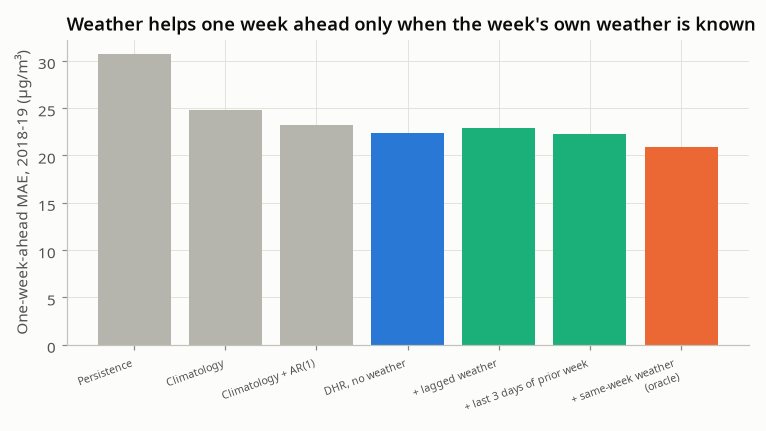

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labs = [m.replace(" (operational)", "").replace(" (ORACLE)", "\n(oracle)") for m in order_]
vals = [piv.loc[m, "both years"] for m in order_]
cols_ = [NEUTRAL, NEUTRAL, NEUTRAL, BLUE, AQUA, AQUA, ORANGE]
ax.bar(range(len(vals)), vals, color=cols_)
ax.set_xticks(range(len(vals)), labs, fontsize=7, rotation=20, ha="right")
ax.set_ylabel("One-week-ahead MAE, 2018-19 (µg/m³)")
ax.set_title("Weather helps one week ahead only when the week's own weather is known")
savefig(fig, "14_oneweek"); plt.show()

## 6. Final outlook for 2020 and validation of the method on 2019
**Procedure (identical for both).** Fit the headline procedure on the years before the target year; simulate 5,000 weekly paths from the fitted model
(53 weeks so every calendar day is covered); apply the calibration rule (fitted only on earlier folds); convert weekly paths to daily PM2.5 by adding a
whole within-week offset vector (Mon–Sun, `log(daily) − log(weekly mean)`, from a training week of the same month), so each simulated week still averages exactly to its simulated weekly mean and day-to-day dependence is kept; classify each day into the CPCB
PM2.5 sub-index bands. Monthly means and band-day counts are computed from the same daily paths. This yields (a) the median and 95% interval of each month's mean PM2.5 and (b) the expected number of days per band.
**This is a PM2.5 band, not the official AQI** (the AQI is the maximum sub-index over all pollutants).
2019 is a genuine out-of-sample test of the whole pipeline; 2020 is the deliverable.

In [13]:
def pipeline(origin, year, folds_for_cal, n=5000):
    tr_ = y.loc[:origin]
    idx = pd.date_range(tr_.index[-1] + pd.Timedelta(weeks=1), periods=53, freq="W-SUN")   # covers every day of `year`
    out = F.dhr(tr_, idx)                          # re-selects K, p, q and trend using data up to `origin` only
    res_, mu_, sd_ = out["res"], out["mu"], out["sd"]
    paths = F.simulate_paths(res_, idx, exog=F.fourier(idx, out["spec"]["K"]), n=n)
    med_gap = float(np.abs(np.median(paths, axis=1) - mu_).mean())
    assert med_gap < 0.03, med_gap                 # simulation agrees with the analytic forecast
    rule = calibration_rule(folds_for_cal)
    f = np.where(pd.DatetimeIndex(idx).month.isin(F.WINTER), rule["f"][True], rule["f"][False])
    paths_c = (mu_ + rule["shift"] * sd_)[:, None] + f[:, None] * (paths - mu_[:, None])
    pools = F.week_offsets_by_month(daily["pm25"].loc[:origin])
    dd, dv = F.daily_paths(paths_c, idx, pools, year)               # daily values whose weekly means equal the weekly paths
    bands = F.daily_band_days(dd, dv)                                # (paths, 12, 6)  band days and monthly means come from the SAME daily paths
    monthly = F.monthly_mean_paths(dd, dv)                           # (12, paths)
    return {"idx": idx, "mu": mu_, "sd": sd_, "paths": paths_c, "bands": bands, "monthly": monthly, "spec": out["spec"], "rule": rule, "res": res_}

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
def month_table(P, year):
    rows = []
    for m in range(12):
        mm = P["monthly"][m]; b = P["bands"][:, m, :]
        row = {"month": month_names[m], "median": np.median(mm), "lo95": np.percentile(mm, 2.5), "hi95": np.percentile(mm, 97.5),
               "P(mean>60)": (mm > 60).mean(), "P(mean>90)": (mm > 90).mean(), "P(mean>120)": (mm > 120).mean()}
        for k, c in enumerate(CATEGORIES):
            row[f"days_{c}"] = b[:, k].mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("month")

# 2019: validation of the pipeline (calibration only from folds 2017-2018, selection only from data to 2018-12-30)
P19 = pipeline(F.ORIGINS[2019], 2019, [2017, 2018])
mt19 = month_table(P19, 2019)
d19 = daily.loc["2019", "pm25"]
act_days = pd.crosstab(d19.index.month, pm25_category(d19.to_numpy()).to_numpy()).reindex(columns=CATEGORIES, fill_value=0)
act_days.index = month_names
act_med = d19.groupby(d19.index.month).mean(); act_med.index = month_names
val = pd.DataFrame({"actual_mean": act_med, "pred_median": mt19["median"], "pred_lo95": mt19["lo95"], "pred_hi95": mt19["hi95"]})
val["inside95"] = (val.actual_mean >= val.pred_lo95) & (val.actual_mean <= val.pred_hi95)
bands_pred = mt19[[f"days_{c}" for c in CATEGORIES]]; bands_pred.columns = CATEGORIES
err_days = (bands_pred - act_days).abs()
val.round(1).to_csv(RESULTS / "fc_outlook_validation_2019_monthly.csv")
pd.concat({"predicted": bands_pred.round(1), "actual": act_days}, axis=1).to_csv(RESULTS / "fc_outlook_validation_2019_days.csv")
key["validation_2019"] = {"months_actual_inside_95": int(val.inside95.sum()), "annual_days_pred": bands_pred.sum().round(1).to_dict(),
                          "annual_days_actual": act_days.sum().to_dict(), "mean_abs_days_error_per_band_month": round(float(err_days.mean().mean()), 2),
                          "poor_or_worse_pred_pct": round(float(bands_pred[["Poor", "Very Poor", "Severe"]].sum().sum() / 365 * 100), 1),
                          "poor_or_worse_actual_pct": round(float(act_days[["Poor", "Very Poor", "Severe"]].sum().sum() / 365 * 100), 1)}
print(key["validation_2019"]); display(val.round(1))
assert np.allclose(P19["bands"].sum(axis=2)[0], [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

{'months_actual_inside_95': 12, 'annual_days_pred': {'Good': 21.5, 'Satisfactory': 75.2, 'Moderate': 67.4, 'Poor': 53.0, 'Very Poor': 113.2, 'Severe': 34.7}, 'annual_days_actual': {'Good': 25, 'Satisfactory': 97, 'Moderate': 78, 'Poor': 58, 'Very Poor': 73, 'Severe': 34}, 'mean_abs_days_error_per_band_month': 1.89, 'poor_or_worse_pred_pct': 55.0, 'poor_or_worse_actual_pct': 45.2}


,actual_mean,pred_median,pred_lo95,pred_hi95,inside95
Jan,204.3,210.3,146.2,299.4,True
Feb,122.3,142.6,94.0,210.6,True
Mar,84.2,101.2,65.7,157.1,True
Apr,82.3,102.0,63.3,164.4,True
May,89.7,100.0,62.4,161.7,True
Jun,63.8,75.2,45.6,123.7,True
Jul,46.7,46.1,27.1,76.8,True
Aug,34.1,43.0,24.4,75.0,True
Sep,40.1,57.0,31.8,101.6,True
Oct,123.7,142.2,79.1,254.9,True


In [14]:
# 2020 deliverable: selection on data to 2019-12-29, calibration from folds 2018 and 2019
P20 = pipeline("2019-12-29", 2020, [2018, 2019])
mt20 = month_table(P20, 2020)
assert np.allclose(P20["bands"].sum(axis=2)[0], [31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
a20 = daily.loc["2020"]["pm25"].dropna()
mt20["actual_mean_2020"] = a20.groupby(a20.index.month).mean().reindex(range(1, 13)).to_numpy()
mt20["actual_days_covered"] = a20.groupby(a20.index.month).count().reindex(range(1, 13)).to_numpy()
mt20.round(3).to_csv(RESULTS / "fc_outlook_2020.csv")
key["outlook_2020_spec"] = {k: v for k, v in P20["spec"].items() if k not in ("inner_mae", "res")}; key["outlook_2020_rule"] = P20["rule"]
display(mt20.round(2))

,median,lo95,hi95,P(mean>60),P(mean>90),P(mean>120),days_Good,days_Satisfactory,days_Moderate,days_Poor,days_Very Poor,days_Severe,actual_mean_2020,actual_days_covered
month,,,,,,,,,,,,,,
Jan,189.96,143.30,253.88,1.00,1.00,1.00,0.00,0.12,0.97,2.94,21.31,5.65,157.11,31.0
Feb,121.39,90.30,164.34,1.00,0.98,0.53,0.04,1.83,6.22,7.83,12.38,0.69,121.48,29.0
Mar,84.68,66.06,109.14,1.00,0.32,0.00,0.27,6.04,12.65,8.04,3.99,0.00,57.51,31.0
Apr,85.74,66.69,111.64,1.00,0.35,0.01,0.16,5.45,12.58,7.88,3.92,0.01,44.94,30.0
May,84.66,66.60,109.10,1.00,0.33,0.00,0.15,6.14,12.81,7.90,3.98,0.01,55.45,31.0
Jun,62.86,48.19,81.47,0.63,0.00,0.00,1.36,13.95,10.63,3.24,0.82,0.00,46.69,30.0
Jul,38.77,30.34,50.21,0.00,0.00,0.00,8.84,19.49,2.48,0.17,0.01,0.00,54.01,1.0
Aug,35.72,27.73,46.30,0.00,0.00,0.00,10.87,18.69,1.38,0.06,0.00,0.00,NaN,NaN
Sep,45.38,35.48,59.24,0.02,0.00,0.00,5.92,18.01,5.38,0.64,0.05,0.00,NaN,NaN


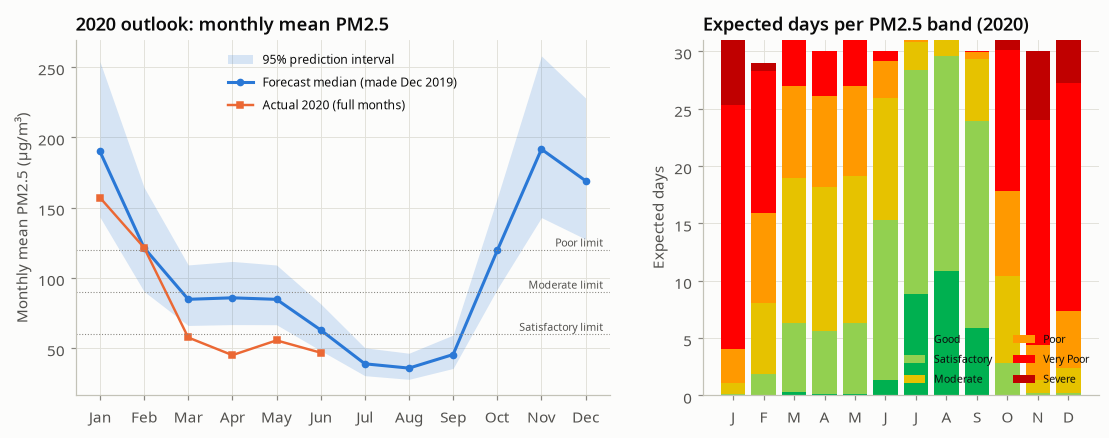

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]; xs = np.arange(12)
ax.fill_between(xs, mt20["lo95"], mt20["hi95"], color=BLUE, alpha=0.18, lw=0, label="95% prediction interval")
ax.plot(xs, mt20["median"], color=BLUE, lw=2, marker="o", ms=4, label="Forecast median (made Dec 2019)")
ok = mt20["actual_days_covered"] >= 28
ax.plot(xs[ok], mt20.loc[ok, "actual_mean_2020"], color=ORANGE, lw=1.6, marker="s", ms=4, label="Actual 2020 (full months)")
for yv, lab in [(60, "Satisfactory limit"), (90, "Moderate limit"), (120, "Poor limit")]:
    ax.axhline(yv, color=MUTED, lw=0.7, ls=":"); ax.text(11.4, yv, lab, fontsize=7, va="bottom", ha="right", color=INK_2)
ax.set_xticks(xs, month_names); ax.set_ylabel("Monthly mean PM2.5 (µg/m³)"); ax.legend(fontsize=8, loc="upper center")
ax.set_title("2020 outlook: monthly mean PM2.5")
ax = axes[1]
colors = {"Good": "#00B050", "Satisfactory": "#92D050", "Moderate": "#E6C200", "Poor": "#FF9900", "Very Poor": "#FF0000", "Severe": "#C00000"}
bottom = np.zeros(12)
for c in CATEGORIES:
    v = mt20[f"days_{c}"].to_numpy(); ax.bar(xs, v, bottom=bottom, color=colors[c], width=0.8, label=c); bottom += v
ax.set_xticks(xs, [m[0] for m in month_names]); ax.set_ylabel("Expected days"); ax.set_title("Expected days per PM2.5 band (2020)")
ax.legend(fontsize=7, ncols=2, loc="lower right")
savefig(fig, "15_outlook_2020"); plt.show()

## 7. Case study: the 2020 lockdown
Delhi's lockdown began on 25 March 2020. We compare the actual weekly PM2.5 of the ten Sunday-ending weeks 29 March – 31 May (these cover 23 March – 31 May, so two pre-lockdown days are included) with the no-lockdown forecast made on
29 Dec 2019 (calibrated, as above). A second counterfactual uses a version of the same model *with the actual 2020 same-week wind and humidity* (fitted on 2015–2019),
to separate the weather contribution from the rest. Both are descriptive, not causal: they rely on the model being right about the level for 2020, and the model was already about 9% too high in the weeks before the lockdown (sensitivities below).

,actual_mean,cf_median,gap_median_pct,gap_lo95_pct,gap_hi95_pct
no-lockdown forecast,48.7,85.5,-43.1,-52.3,-32.0
weather-adjusted forecast (oracle weather),NaN,78.4,-37.9,-47.8,-26.5


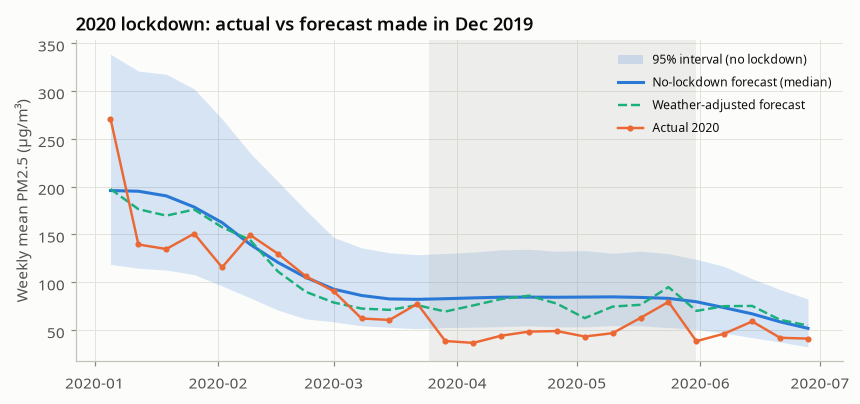

In [16]:
lock_idx = pd.date_range("2020-03-29", "2020-05-31", freq="W-SUN")
act_l = raw.loc[lock_idx].to_numpy()
pos = P20["idx"].get_indexer(lock_idx); assert (pos >= 0).all()
cf = np.exp(P20["paths"][pos]).mean(axis=0)                     # counterfactual mean over the 10 weeks, per simulated path
gap = act_l.mean() / cf - 1
res1 = {"actual_mean": float(act_l.mean()), "cf_median": float(np.median(cf)), "gap_median_pct": float(100 * np.median(gap)),
        "gap_lo95_pct": float(100 * np.percentile(gap, 2.5)), "gap_hi95_pct": float(100 * np.percentile(gap, 97.5))}

# weather-adjusted counterfactual (oracle weather)
wx20 = weather_frame("2019-12-29")[["wind_same", "rh_same"]]
tr_f = y.loc[:"2019-12-29"]; sp_f = P20["spec"]; trend_, d_ = F.TREND_SPECS[sp_f["trend"]]
Xf = lambda ix: pd.concat([F.fourier(ix, sp_f["K"]), wx20.loc[ix]], axis=1)
fit_w = SARIMAX(tr_f, exog=Xf(tr_f.index), order=(sp_f["p"], d_, sp_f["q"]), trend=trend_).fit(disp=False, maxiter=200)
idx_w = pd.date_range("2020-01-05", "2020-06-28", freq="W-SUN")
pw = F.simulate_paths(fit_w, idx_w, exog=Xf(idx_w), n=5000)
fw = fit_w.get_forecast(len(idx_w), exog=Xf(idx_w)); sdw = np.sqrt(fw.var_pred_mean.to_numpy())
f_w = np.where(pd.DatetimeIndex(idx_w).month.isin(F.WINTER), P20["rule"]["f"][True], P20["rule"]["f"][False])
mu_w = fw.predicted_mean.to_numpy(); pw = mu_w[:, None] + f_w[:, None] * (pw - mu_w[:, None])
posw = idx_w.get_indexer(lock_idx)
cfw = np.exp(pw[posw]).mean(axis=0); gapw = act_l.mean() / cfw - 1
res2 = {"cf_median": float(np.median(cfw)), "gap_median_pct": float(100 * np.median(gapw)),
        "gap_lo95_pct": float(100 * np.percentile(gapw, 2.5)), "gap_hi95_pct": float(100 * np.percentile(gapw, 97.5))}
lock = pd.DataFrame({"no-lockdown forecast": res1, "weather-adjusted forecast (oracle weather)": res2}).T
lock.round(1).to_csv(RESULTS / "fc_lockdown.csv"); display(lock.round(1))
key["lockdown"] = {"plain": res1, "weather_adjusted": res2}

fig, ax = plt.subplots(figsize=(9, 3.8))
show_idx = P20["idx"][:26]
lo_, hi_ = np.percentile(np.exp(P20["paths"][:26]), [2.5, 97.5], axis=1)
pd.DataFrame({"lo95": lo_, "median": np.exp(np.median(P20["paths"][:26], axis=1)), "hi95": hi_,
              "weather_adj_median": np.exp(np.median(pw, axis=1)), "actual": raw.reindex(show_idx).to_numpy()}, index=show_idx).rename_axis("date").to_csv(RESULTS / "fc_weekly_2020.csv")
ax.fill_between(show_idx, lo_, hi_, color=BLUE, alpha=0.18, lw=0, label="95% interval (no lockdown)")
ax.plot(show_idx, np.exp(np.median(P20["paths"][:26], axis=1)), color=BLUE, lw=2, label="No-lockdown forecast (median)")
ax.plot(idx_w, np.exp(np.median(pw, axis=1)), color=AQUA, lw=1.6, ls="--", label="Weather-adjusted forecast")
ax.plot(show_idx, raw.loc[show_idx], color=ORANGE, lw=1.6, marker="o", ms=3, label="Actual 2020")
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color=NEUTRAL, alpha=0.2, lw=0)
ax.set_ylabel("Weekly mean PM2.5 (µg/m³)"); ax.legend(fontsize=8); ax.set_title("2020 lockdown: actual vs forecast made in Dec 2019")
savefig(fig, "16_lockdown"); plt.show()

### Sensitivity of the lockdown gap
The gap to a forecast is only as good as the forecast's level. Checks: (a) the same model's gap in the 12 weeks *before* the lockdown (5 Jan – 22 Mar), and the lockdown gap adjusted for it;
(b) a 9-week window starting 5 April (no pre-lockdown days); (c) other level specifications (constant, random-walk); (d) a mean-bias shift shrunk from the 2018–19 errors (post-hoc);
(e) a placebo: the same calendar weeks of 2019 against the 2019 forecast pipeline.

In [17]:
def gap_stats(paths, idx_, weeks):
    pos_ = pd.DatetimeIndex(idx_).get_indexer(weeks); assert (pos_ >= 0).all()
    cf_ = np.exp(paths[pos_]).mean(axis=0); g = raw.reindex(weeks).mean() / cf_ - 1
    return float(100 * np.median(g)), float(100 * np.percentile(g, 2.5)), float(100 * np.percentile(g, 97.5))

wk_pre = pd.date_range("2020-01-05", "2020-03-22", freq="W-SUN")
wk_9 = pd.date_range("2020-04-05", "2020-05-31", freq="W-SUN")
rule20 = P20["rule"]; f20 = np.where(pd.DatetimeIndex(P20["idx"]).month.isin(F.WINTER), rule20["f"][True], rule20["f"][False])
def spec_paths(trend, K, p_, q_):
    r_ = F._fit_dhr(y.loc[:"2019-12-29"], K, p_, q_, trend)
    pa = F.simulate_paths(r_, P20["idx"], exog=F.fourier(P20["idx"], K), n=5000)
    fc_ = r_.get_forecast(len(P20["idx"]), exog=F.fourier(P20["idx"], K)); mu_ = fc_.predicted_mean.to_numpy()
    return mu_[:, None] + f20[:, None] * (pa - mu_[:, None]), mu_, np.sqrt(fc_.var_pred_mean.to_numpy())

rows = []
def add(name, paths, idx_=P20["idx"]):
    pre = gap_stats(paths, idx_, wk_pre); l10 = gap_stats(paths, idx_, lock_idx); l9 = gap_stats(paths, idx_, wk_9)
    adj = 100 * ((1 + l10[0] / 100) / (1 + pre[0] / 100) - 1)
    rows.append({"counterfactual": name, "pre_lockdown_gap_pct": pre[0], "lockdown_gap_10wk_pct": l10[0], "lo95": l10[1], "hi95": l10[2],
                 "gap_9wk_from_5Apr_pct": l9[0], "lockdown_gap_adjusted_for_pre_gap_pct": adj})
add("selected spec (linear, K=5, AR1), headline", P20["paths"])
for nm, (tr_, K_, p_, q_) in {"constant level": ("const", 5, 1, 0), "random-walk level (ARIMA errors)": ("rw", 5, 1, 1)}.items():
    pa_, _, _ = spec_paths(tr_, K_, p_, q_); add(nm, pa_)
sh20 = shrunk_shift([2018, 2019])
add("headline + shrunk mean-bias shift (post-hoc)", P20["paths"] + sh20 * P20["sd"][:, None])
# placebo: 2019 pipeline, same calendar weeks of 2019
wk_pl = pd.date_range("2019-03-31", "2019-06-02", freq="W-SUN")
pl = gap_stats(P19["paths"], P19["idx"], wk_pl)
rows.append({"counterfactual": "PLACEBO: same weeks of 2019 vs 2019 forecast", "pre_lockdown_gap_pct": gap_stats(P19["paths"], P19["idx"], pd.date_range("2019-01-06", "2019-03-24", freq="W-SUN"))[0],
             "lockdown_gap_10wk_pct": pl[0], "lo95": pl[1], "hi95": pl[2], "gap_9wk_from_5Apr_pct": np.nan, "lockdown_gap_adjusted_for_pre_gap_pct": np.nan})
sens = pd.DataFrame(rows); sens.round(1).to_csv(RESULTS / "fc_lockdown_sensitivity.csv", index=False); display(sens.round(1))
key["lockdown_sensitivity"] = sens.round(2).set_index("counterfactual").to_dict("index")

,counterfactual,pre_lockdown_gap_pct,lockdown_gap_10wk_pct,lo95,hi95,gap_9wk_from_5Apr_pct,lockdown_gap_adjusted_for_pre_gap_pct
0,"selected spec (linear, K=5, AR1), headline",-11.3,-43.1,-52.3,-32.0,-41.8,-35.8
1,constant level,-22.3,-50.9,-59.6,-40.0,-49.8,-36.8
2,random-walk level (ARIMA errors),-9.7,-43.2,-55.2,-28.8,-42.0,-37.1
3,headline + shrunk mean-bias shift (post-hoc),-2.4,-37.3,-47.6,-25.1,-35.9,-35.8
4,PLACEBO: same weeks of 2019 vs 2019 forecast,-9.0,-15.0,-43.4,28.1,NaN,NaN


## 8. Summary numbers

In [18]:
m_sel = bt[bt.model == SEL].set_index("fold"); m_clim = bt[bt.model == "Climatology"].set_index("fold")
key["backtest"] = {"mae_selected": m_sel["MAE"].round(2).to_dict(), "mae_climatology": m_clim["MAE"].round(2).to_dict(),
                   "coverage_selected": m_sel["coverage"].round(3).to_dict(),
                   "sarima_D1_mae": bt[bt.model == "SARIMA D=1"].set_index("fold")["MAE"].round(2).to_dict(),
                   "sarima_D0_mae": bt[bt.model == "SARIMA D=0"].set_index("fold")["MAE"].round(2).to_dict(),
                   "lstm_mae": bt[bt.model == "LSTM (small)"].set_index("fold")["MAE"].round(2).to_dict(),
                   "specs": {int(f): {k: v for k, v in s.items() if k != "inner_mae"} for f, s in specs.items()}}
key["diagnostics_selected_2019_fold"] = {k: round(float(v), 4) for k, v in diag.iloc[0].items() if k != "LB_p_lag10_ALL_residuals (draft's mistake)"}
(RESULTS / "key_numbers_forecast.json").write_text(json.dumps(key, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
key

{'sarima_d0_const': {2017: {'no constant': 76.92,
   'with constant': 44.87,
   'Climatology (reference)': 31.0},
  2018: {'no constant': 60.98,
   'with constant': 42.84,
   'Climatology (reference)': 21.77},
  2019: {'no constant': 92.11,
   'with constant': 44.1,
   'Climatology (reference)': 27.82}},
 'nonconverged_rejected_per_origin': {2017: 6, 2018: 3, 2019: 5},
 'sarima_D1_maS_coef': -0.988,
 'sarima_D1_maS_se': 8.259,
 'calibration_rule_2019': {'f': {True: 1.3343095497324873,
   False: 1.421532404826579},
  'shift': 0.0,
  'by_fold_mean_z': {2017: -0.66, 2018: -0.45},
  'recentre': False},
 'coverage_2019_raw': 0.9038461538461539,
 'coverage_2019_calibrated': 0.9615384615384616,
 'calibration_2019_all': {'Model-based Gaussian': {'MAE': 25.694,
   'coverage': 0.904,
   'width': 125.08,
   'winkler': 174.878,
   'bias': -8.492},
  'Calibrated (season scale)': {'MAE': 25.694,
   'coverage': 0.962,
   'width': 178.655,
   'winkler': 192.721,
   'bias': -8.492},
  'Season scale + s